In [ ]:
# Робота з даними
import numpy as np
import pandas as pd

# Візуалізація
import matplotlib.pyplot as plt
import seaborn as sns

# Підготовка даних
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

# Моделі класифікації
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# Метрики оцінювання
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

# Інші інструменти
from pathlib import Path
import joblib

# Налаштування відображення
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Бібліотеки успішно імпортовано.")


Бібліотеки успішно імпортовано.


In [ ]:
# Шлях до результатів першого етапу EDA
data_path = Path("loan_data_eda.csv")

# Завантаження
df = pd.read_csv(data_path)

# Загальна інформація
print("Розмір набору даних:", df.shape)

print("\nТипи змінних:")
df.info()

print("\nПерші 5 спостережень:")
display(df.head())

print("\nРозподіл цільової змінної:")
display(
    df["Loan_Status"]
    .value_counts()
    .sort_index()
    .to_frame("Кількість")
)

print("\nПропущені значення:")
display(
    df.isna().sum().to_frame("Пропуски")
)


Розмір набору даних: (381, 13)

Типи змінних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             376 non-null    object 
 1   Married            381 non-null    object 
 2   Dependents         373 non-null    object 
 3   Education          381 non-null    object 
 4   Self_Employed      360 non-null    object 
 5   ApplicantIncome    381 non-null    int64  
 6   CoapplicantIncome  381 non-null    float64
 7   LoanAmount         381 non-null    float64
 8   Loan_Amount_Term   370 non-null    float64
 9   Credit_History     351 non-null    float64
 10  Property_Area      381 non-null    object 
 11  Loan_Status        381 non-null    int64  
 12  LoanIncomeRatio    381 non-null    float64
dtypes: float64(5), int64(2), object(6)
memory usage: 38.8+ KB

Перші 5 спостережень:


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,LoanIncomeRatio
0,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0,0.021015
1,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1,0.022000
2,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1,0.024287
3,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1,0.023500
4,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,1,0.024682



Розподіл цільової змінної:


,Кількість
Loan_Status,
0,110
1,271



Пропущені значення:


,Пропуски
Gender,5
Married,0
Dependents,8
Education,0
Self_Employed,21
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,11
Credit_History,30


У результаті завантаження підготовленого набору даних отримано 381 спостереження та 13 змінних, з яких 12 є потенційними предикторами, а Loan_Status — цільовою змінною.
Цільова змінна має бінарний формат: 0 — відхилена заявка, 1 — схвалена заявка. Із 381 заявки схвалено 271 (71,13%), відхилено 110 (28,87%). Отже, спостерігається помірний дисбаланс класів на користь схвалених кредитів.
У п'яти предикторах виявлено пропущені значення. Найбільша їх кількість спостерігається у Credit_History (30), Self_Employed (21) та Loan_Amount_Term (11). Пропуски необхідно заповнити перед навчанням моделей.

In [ ]:

# Формування матриці предикторів і цільової змінної

X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"]

print("Розмір матриці предикторів X:", X.shape)
print("Розмір цільової змінної y:", y.shape)

# Розділення даних на навчальну та тестову вибірки

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Контроль розмірів вибірок

print("\nРозміри вибірок:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Перевірка розподілу класів

class_distribution = pd.DataFrame({
    "Повна вибірка, %": (
        y.value_counts(normalize=True) * 100
    ),
    "Навчальна вибірка, %": (
        y_train.value_counts(normalize=True) * 100
    ),
    "Тестова вибірка, %": (
        y_test.value_counts(normalize=True) * 100
    )
}).sort_index().round(2)

class_distribution.index.name = "Loan_Status"

print("\nРозподіл класів:")
display(class_distribution)

Розмір матриці предикторів X: (381, 12)
Розмір цільової змінної y: (381,)

Розміри вибірок:
X_train: (304, 12)
X_test: (77, 12)
y_train: (304,)
y_test: (77,)

Розподіл класів:


,"Повна вибірка, %","Навчальна вибірка, %","Тестова вибірка, %"
Loan_Status,,,
0,28.87,28.95,28.57
1,71.13,71.05,71.43


Для побудови моделей машинного навчання сформовано матрицю предикторів X, що містить 381 спостереження та 12 незалежних ознак, і цільову змінну y — Loan_Status.
Дані розділено на навчальну (304 спостереження, 79,79%) та тестову (77 спостережень, 20,21%) вибірки.
Застосування стратифікованого розділення дозволило зберегти початкові пропорції класів. Частка схвалених кредитів становить 71,05% у навчальній вибірці та 71,43% у тестовій, тоді як частка відхилених — відповідно 28,95% і 28,57%.

In [ ]:
# Визначення числових і категоріальних ознак

numeric_features = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "LoanIncomeRatio"
]

categorical_features = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area"
]

# Pipeline для числових ознак

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline для категоріальних ознак

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Об'єднання обробки ознак

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Перевірка розподілу ознак

print("Числові ознаки:", len(numeric_features))
print(numeric_features)

print("\nКатегоріальні ознаки:", len(categorical_features))
print(categorical_features)

print("\nЗагальна кількість вихідних ознак:")
print(len(numeric_features) + len(categorical_features))

# Перевірка відповідності матриці X

assert set(numeric_features + categorical_features) == set(X.columns)

print("\nУсі предиктори враховано.")
print("ColumnTransformer успішно створено.")


Числові ознаки: 5
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'LoanIncomeRatio']

Категоріальні ознаки: 7
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']

Загальна кількість вихідних ознак:
12

Усі предиктори враховано.
ColumnTransformer успішно створено.


Для попередньої обробки даних визначено 12 предикторів, з яких 5 віднесено до числових та 7 — до категоріальних ознак. Визначено повний набір процедур попередньої обробки, необхідних для подальшого навчання класифікаторів.
Побудову моделей машинного навчання почнемо з моделі Logistic Regression.

Матриця помилок Logistic Regression:
[[ 44  44]
 [  9 207]]


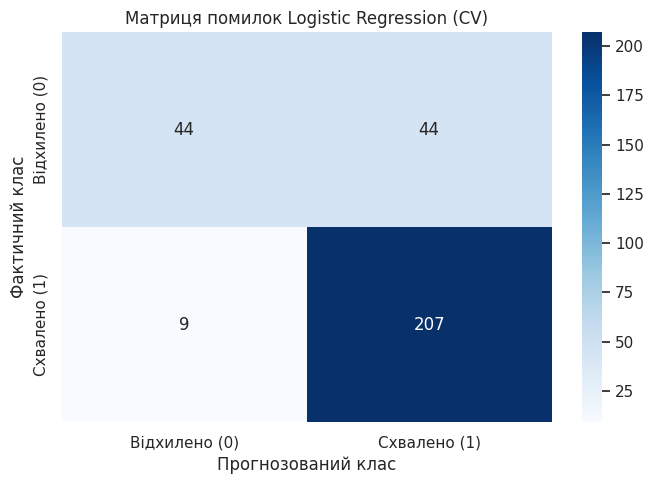


Звіт класифікації:
               precision    recall  f1-score   support

Відхилено (0)     0.8302    0.5000    0.6241        88
 Схвалено (1)     0.8247    0.9583    0.8865       216

     accuracy                         0.8257       304
    macro avg     0.8274    0.7292    0.7553       304
 weighted avg     0.8263    0.8257    0.8106       304



In [ ]:
# Створення Pipeline логістичної регресії

logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# Налаштування перехресної валідації

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Метрики оцінювання

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Перехресна валідація

logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

from sklearn.model_selection import cross_val_predict

# Прогнози перехресної валідації
y_pred_cv = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

# Матриця помилок
cm = confusion_matrix(
    y_train,
    y_pred_cv,
    labels=[0, 1]
)

print("Матриця помилок Logistic Regression:")
print(cm)

# Візуалізація
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Відхилено (0)", "Схвалено (1)"],
    yticklabels=["Відхилено (0)", "Схвалено (1)"]
)

plt.xlabel("Прогнозований клас")
plt.ylabel("Фактичний клас")
plt.title("Матриця помилок Logistic Regression (CV)")

plt.tight_layout()
plt.show()

# Детальний звіт за класами
print("\nЗвіт класифікації:")

print(
    classification_report(
        y_train,
        y_pred_cv,
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)



За результатами перехресної валідації логістична регресія продемонструвала загальну точність класифікації (Accuracy) на рівні 82,57%. Із 304 кредитних заявок модель правильно класифікувала 251, а помилково — 53.
Для класу схвалених кредитів (Loan_Status = 1) отримано високі значення Recall (95,83%) та F1-score (0,8865), що свідчить про здатність моделі правильно розпізнавати переважну більшість схвалених заявок.
Водночас для класу відхилених кредитів (Loan_Status = 0) показник Recall становить лише 50,00%, а F1-score — 0,6241. Зокрема, 44 із 88 фактично відхилених заявок модель помилково віднесла до схвалених. Це свідчить про недостатню чутливість алгоритму до нульового класу.
Переходимо до наступної моделі - DecisionTreeClassifier.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Параметри для оптимізації Logistic Regression
params_logistic = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"]
}

# Пошук найкращих гіперпараметрів
grid_logistic = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=params_logistic,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    return_train_score=True
)

# Навчання та пошук оптимальних параметрів
grid_logistic.fit(X_train, y_train)

# Результати оптимізації
print("Найкращі параметри Logistic Regression:")
print(grid_logistic.best_params_)

print("\nКількість перевірених комбінацій:")
print(len(grid_logistic.cv_results_["params"]))

# Прогнози вкладеної перехресної валідації
y_pred_logistic_opt_cv = cross_val_predict(
    grid_logistic,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

# Повний звіт класифікації
print("\nЗвіт класифікації Logistic Regression (Optimized):")

print(
    classification_report(
        y_train,
        y_pred_logistic_opt_cv,
        labels=[0, 1],
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)

Найкращі параметри Logistic Regression:
{'classifier__C': 0.1, 'classifier__solver': 'lbfgs'}

Кількість перевірених комбінацій:
10

Звіт класифікації Logistic Regression (Optimized):
               precision    recall  f1-score   support

Відхилено (0)     0.9091    0.4545    0.6061        88
 Схвалено (1)     0.8154    0.9815    0.8908       216

     accuracy                         0.8289       304
    macro avg     0.8622    0.7180    0.7484       304
 weighted avg     0.8425    0.8289    0.8083       304



За допомогою GridSearchCV було перевірено 10 комбінацій гіперпараметрів логістичної регресії. Найкращою виявилася комбінація C = 0.1 та solver = lbfgs.
Оптимізація підвищила якість прогнозування схвалених заявок, але погіршила здатність моделі виявляти відхилені. За критерієм F1-score класу 1, оптимізована Logistic Regression має незначну перевагу за цим показником.
Переходимо до наступної моделі - DecisionTreeClassifier.

Матриця помилок Decision Tree Classifier:
[[ 48  40]
 [ 32 184]]


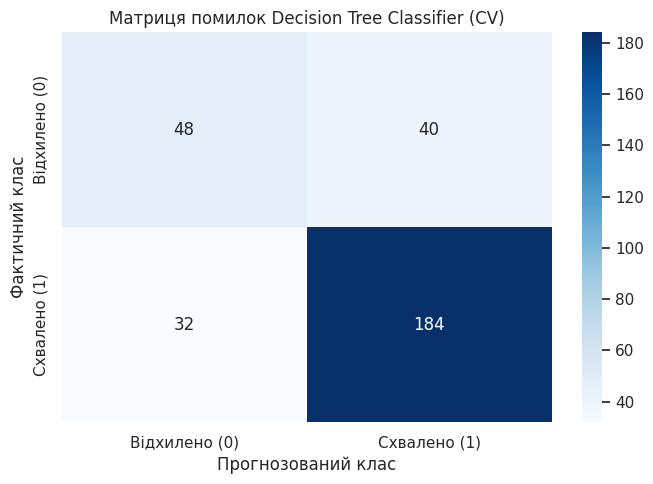


Звіт класифікації:
               precision    recall  f1-score   support

Відхилено (0)     0.6000    0.5455    0.5714        88
 Схвалено (1)     0.8214    0.8519    0.8364       216

     accuracy                         0.7632       304
    macro avg     0.7107    0.6987    0.7039       304
 weighted avg     0.7573    0.7632    0.7597       304



In [ ]:
# Створення моделі дерева рішень
decision_tree = DecisionTreeClassifier(
    random_state=42
)

# Створення Pipeline
decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", decision_tree)
])

# Перехресна валідація
decision_tree_cv = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# Прогнози перехресної валідації
y_pred_tree_cv = cross_val_predict(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

# Матриця помилок
cm_tree = confusion_matrix(
    y_train,
    y_pred_tree_cv,
    labels=[0, 1]
)

print("Матриця помилок Decision Tree Classifier:")
print(cm_tree)

# Візуалізація
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Відхилено (0)", "Схвалено (1)"],
    yticklabels=["Відхилено (0)", "Схвалено (1)"]
)

plt.xlabel("Прогнозований клас")
plt.ylabel("Фактичний клас")
plt.title("Матриця помилок Decision Tree Classifier (CV)")

plt.tight_layout()
plt.show()

# Детальний звіт за класами
print("\nЗвіт класифікації:")

print(
    classification_report(
        y_train,
        y_pred_tree_cv,
        labels=[0, 1],
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)

За результатами п'ятикратної перехресної валідації базова модель Decision Tree Classifier забезпечила загальну точність класифікації (Accuracy) 76,32%. Із 304 кредитних заявок правильно класифіковано 232, помилково — 72.
Порівняно з Logistic Regression дерево рішень продемонструвало нижчі значення Accuracy (76,32% проти 82,57%), F1-score для схвалених кредитів (0,8364 проти 0,8865) та Macro F1-score (0,7039 проти 0,7553).
Водночас Recall для відхилених заявок у Decision Tree дещо вищий (54,55% проти 50,00%), що свідчить про кращу здатність виявляти частину негативного класу, хоча це супроводжується більшою кількістю помилкових відмов.

In [ ]:
# Параметри для оптимізації Decision Tree Classifier
params_tree = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__criterion": ["gini", "entropy"]
}

# Пошук найкращих гіперпараметрів
grid_tree = GridSearchCV(
    estimator=decision_tree_pipeline,
    param_grid=params_tree,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    return_train_score=True
)

# Навчання та пошук оптимальних параметрів
grid_tree.fit(X_train, y_train)

# Результати оптимізації
print("Найкращі параметри Decision Tree Classifier:")
print(grid_tree.best_params_)

print("\nКількість перевірених комбінацій:")
print(len(grid_tree.cv_results_["params"]))

# Прогнози вкладеної перехресної валідації
y_pred_tree_opt_cv = cross_val_predict(
    grid_tree,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

# Повний звіт класифікації
print("\nЗвіт класифікації Decision Tree Classifier (Optimized):")

print(
    classification_report(
        y_train,
        y_pred_tree_opt_cv,
        labels=[0, 1],
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)

Найкращі параметри Decision Tree Classifier:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Кількість перевірених комбінацій:
90

Звіт класифікації Decision Tree Classifier (Optimized):
               precision    recall  f1-score   support

Відхилено (0)     0.7857    0.5000    0.6111        88
 Схвалено (1)     0.8226    0.9444    0.8793       216

     accuracy                         0.8158       304
    macro avg     0.8041    0.7222    0.7452       304
 weighted avg     0.8119    0.8158    0.8017       304



Найкращою виявилася конфігурація з критерієм розбиття entropy, максимальною глибиною дерева max_depth=3, мінімальною кількістю спостережень у листовому вузлі min_samples_leaf=5 та параметром min_samples_split=2.
Водночас якість розпізнавання відхилених кредитних заявок залишається обмеженою: Recall класу 0 становить 0.5000, а F1-score — 0.6111. Отже, модель усе ще має труднощі з виявленням заявок, які фактично були відхилені.
Порівняння з оптимізованою Logistic Regression показало, що логістична регресія забезпечує дещо вищий F1-score для класу 1 (0.8908 проти 0.8793).
Наступна модель - RandomForestClasifier.

Матриця помилок Random Forest Classifier:
[[ 44  44]
 [  8 208]]


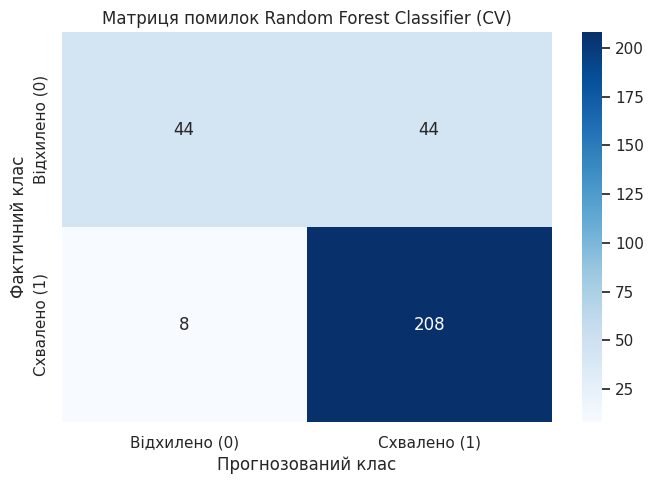


Звіт класифікації:
               precision    recall  f1-score   support

Відхилено (0)     0.8462    0.5000    0.6286        88
 Схвалено (1)     0.8254    0.9630    0.8889       216

     accuracy                         0.8289       304
    macro avg     0.8358    0.7315    0.7587       304
 weighted avg     0.8314    0.8289    0.8135       304



In [19]:
# Створення моделі Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Створення Pipeline
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", random_forest)
])

# Перехресна валідація
random_forest_cv = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# Прогнози перехресної валідації
y_pred_forest_cv = cross_val_predict(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

# Матриця помилок
cm_forest = confusion_matrix(
    y_train,
    y_pred_forest_cv,
    labels=[0, 1]
)

print("Матриця помилок Random Forest Classifier:")
print(cm_forest)

# Візуалізація
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_forest,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Відхилено (0)", "Схвалено (1)"],
    yticklabels=["Відхилено (0)", "Схвалено (1)"]
)

plt.xlabel("Прогнозований клас")
plt.ylabel("Фактичний клас")
plt.title("Матриця помилок Random Forest Classifier (CV)")

plt.tight_layout()
plt.show()

# Детальний звіт за класами
print("\nЗвіт класифікації:")

print(
    classification_report(
        y_train,
        y_pred_forest_cv,
        labels=[0, 1],
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)



Для прогнозування результатів розгляду кредитних заявок побудовано модель Random Forest Classifier, що використовує набір із 100 дерев рішень. Оцінювання ефективності здійснено за допомогою перехресної валідації.
Порівняння з попередніми моделями показало, що Random Forest забезпечує вищий F1-score для класу 1, ніж оптимізована Decision Tree Classifier (0.8889 проти 0.8793), та лише незначно поступається оптимізованій Logistic Regression (0.8908).

In [21]:
# Параметри для оптимізації Random Forest
params_forest = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5, 10, None],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__max_features": ["sqrt", "log2"]
}

# Пошук найкращих гіперпараметрів
grid_forest = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=params_forest,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    return_train_score=True
)

# Навчання та пошук оптимальних параметрів
grid_forest.fit(X_train, y_train)

# Найкраща модель
best_forest = grid_forest.best_estimator_

# Результати оптимізації
print("Найкращі параметри Random Forest Classifier:")
print(grid_forest.best_params_)

print("\nКількість перевірених комбінацій:")
print(len(grid_forest.cv_results_["params"]))

# Прогнози вкладеної перехресної валідації
y_pred_forest_opt_cv = cross_val_predict(
    grid_forest,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

# Повний звіт класифікації
print("\nЗвіт класифікації Random Forest Classifier (Optimized):")

print(
    classification_report(
        y_train,
        y_pred_forest_opt_cv,
        labels=[0, 1],
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)


Найкращі параметри Random Forest Classifier:
{'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Кількість перевірених комбінацій:
96

Звіт класифікації Random Forest Classifier (Optimized):
               precision    recall  f1-score   support

Відхилено (0)     0.9348    0.4886    0.6418        88
 Схвалено (1)     0.8256    0.9861    0.8987       216

     accuracy                         0.8421       304
    macro avg     0.8802    0.7374    0.7703       304
 weighted avg     0.8572    0.8421    0.8244       304



Найкращі результати отримано для моделі зі 100 деревами, максимальною глибиною 3, параметром max_features='sqrt', мінімальною кількістю спостережень у листі 1 та мінімальною кількістю спостережень для розбиття вузла 2.
Порівняння з оптимізованими моделями Logistic Regression і Decision Tree Classifier показало, що Random Forest має найвищий F1-score для класу 1 (0.8987), а також найкращі значення Accuracy (0.8421) та Macro F1 (0.7703).
Водночас модель характеризується порівняно низькою повнотою розпізнавання відхилених кредитних заявок (Recall класу 0 = 0.4886), що свідчить про ризик помилкового схвалення частини заявок.
Наступна модель - XGBoost Classifier.

Матриця помилок XGBoost Classifier:
[[ 49  39]
 [ 18 198]]


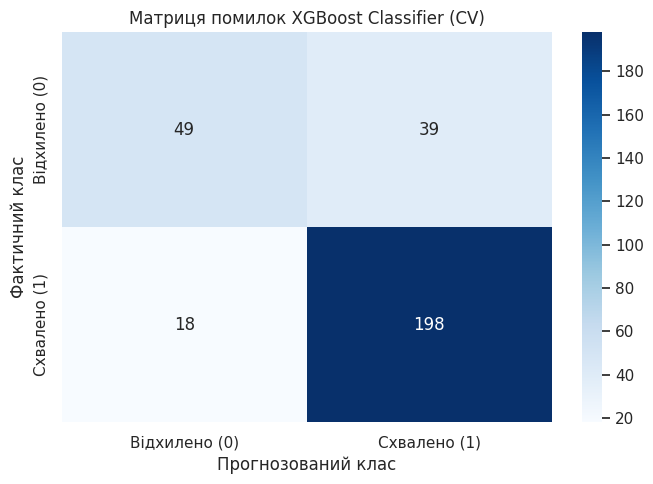


Звіт класифікації:
               precision    recall  f1-score   support

Відхилено (0)     0.7313    0.5568    0.6323        88
 Схвалено (1)     0.8354    0.9167    0.8742       216

     accuracy                         0.8125       304
    macro avg     0.7834    0.7367    0.7532       304
 weighted avg     0.8053    0.8125    0.8041       304



In [22]:
from xgboost import XGBClassifier

# Створення моделі XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

# Створення Pipeline
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

# Перехресна валідація
xgb_cv = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# Прогнози перехресної валідації
y_pred_xgb_cv = cross_val_predict(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)

# Матриця помилок
cm_xgb = confusion_matrix(
    y_train,
    y_pred_xgb_cv,
    labels=[0, 1]
)

print("Матриця помилок XGBoost Classifier:")
print(cm_xgb)

# Візуалізація
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Відхилено (0)", "Схвалено (1)"],
    yticklabels=["Відхилено (0)", "Схвалено (1)"]
)

plt.xlabel("Прогнозований клас")
plt.ylabel("Фактичний клас")
plt.title("Матриця помилок XGBoost Classifier (CV)")

plt.tight_layout()
plt.show()

# Детальний звіт за класами
print("\nЗвіт класифікації:")

print(
    classification_report(
        y_train,
        y_pred_xgb_cv,
        labels=[0, 1],
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)

За результатами перехресної валідації базова модель XGBoost Classifier продемонструвала Accuracy 0.8125, Precision 0.8354, Recall 0.9167 та F1-score 0.8742 для класу схвалених кредитних заявок.
Порівняно з іншими базовими моделями XGBoost поступається Logistic Regression і Random Forest за показником F1-score класу 1, проте забезпечує вищий Recall для класу відхилених кредитних заявок (0.5568).

In [23]:
# Параметри для оптимізації XGBoost
params_xgb = {
    "classifier__n_estimators": [50, 100, 200],
    "classifier__max_depth": [2, 3, 5],
    "classifier__learning_rate": [0.01, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0]
}

# Пошук найкращих гіперпараметрів
grid_xgb = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=params_xgb,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    return_train_score=True
)

# Навчання та пошук оптимальних параметрів
grid_xgb.fit(X_train, y_train)

# Результати оптимізації
print("Найкращі параметри XGBoost Classifier:")
print(grid_xgb.best_params_)

print("\nКількість перевірених комбінацій:")
print(len(grid_xgb.cv_results_["params"]))

# Прогнози вкладеної перехресної валідації
y_pred_xgb_opt_cv = cross_val_predict(
    grid_xgb,
    X_train,
    y_train,
    cv=cv,
    n_jobs=1
)

# Повний звіт класифікації
print("\nЗвіт класифікації XGBoost Classifier (Optimized):")

print(
    classification_report(
        y_train,
        y_pred_xgb_opt_cv,
        labels=[0, 1],
        target_names=[
            "Відхилено (0)",
            "Схвалено (1)"
        ],
        digits=4,
        zero_division=0
    )
)

Найкращі параметри XGBoost Classifier:
{'classifier__colsample_bytree': 0.8, 'classifier__learning_rate': 0.01, 'classifier__max_depth': 2, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}

Кількість перевірених комбінацій:
72

Звіт класифікації XGBoost Classifier (Optimized):
               precision    recall  f1-score   support

Відхилено (0)     0.8980    0.5000    0.6423        88
 Схвалено (1)     0.8275    0.9769    0.8960       216

     accuracy                         0.8388       304
    macro avg     0.8627    0.7384    0.7692       304
 weighted avg     0.8479    0.8388    0.8225       304



За результатами оптимізації гіперпараметрів моделі XGBoost Classifier за допомогою GridSearchCV встановлено покращення її класифікаційної здатності. Показник Accuracy зріс із 0.8125 до 0.8388, а F1-score для класу схвалених кредитів — із 0.8742 до 0.8960. Водночас спостерігається зниження повноти розпізнавання відхилених заявок із 0.5568 до 0.5000.

Порівняння чотирьох оптимізованих моделей показало, що найвищі значення Accuracy (0.8421) та F1-score класу 1 (0.8987) отримано для Random Forest Classifier. Модель XGBoost продемонструвала близькі результати. Остаточний вибір алгоритму потребує оцінювання на незалежній тестовій вибірці.

In [24]:
# Оптимізовані моделі
models = {
    "Logistic Regression": grid_logistic.best_estimator_,
    "Decision Tree": grid_tree.best_estimator_,
    "Random Forest": grid_forest.best_estimator_,
    "XGBoost": grid_xgb.best_estimator_
}

# Збереження результатів
results = []

# Оцінювання моделей
for name, model in models.items():

    # Прогноз класів
    y_pred = model.predict(X_test)

    # Прогноз імовірностей класу 1
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Recall (0)": recall_score(
            y_test, y_pred,
            pos_label=0,
            zero_division=0
        )
    })

# Порівняльна таблиця
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("Порівняння оптимізованих моделей на тестовій вибірці:")

display(comparison_df.round(4))

Порівняння оптимізованих моделей на тестовій вибірці:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC,Recall (0)
0,Logistic Regression,0.8571,0.8333,1.0000,0.9091,0.8405,0.5000
1,Random Forest,0.8571,0.8333,1.0000,0.9091,0.8000,0.5000
2,XGBoost,0.8571,0.8333,1.0000,0.9091,0.8128,0.5000
3,Decision Tree,0.8312,0.8387,0.9455,0.8889,0.7558,0.5455


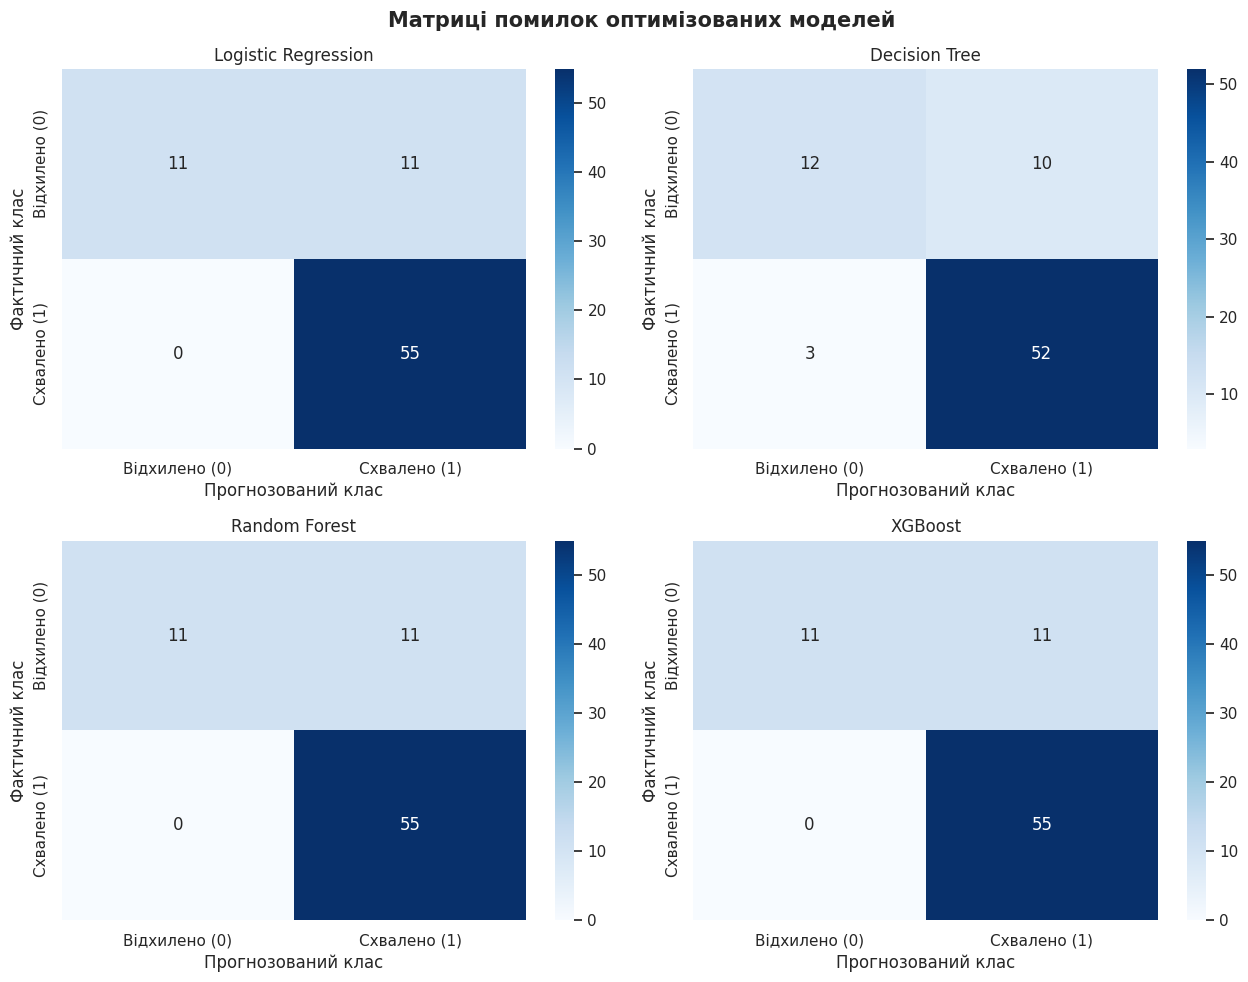

In [25]:
# Оптимізовані моделі
models = {
    "Logistic Regression": grid_logistic.best_estimator_,
    "Decision Tree": grid_tree.best_estimator_,
    "Random Forest": grid_forest.best_estimator_,
    "XGBoost": grid_xgb.best_estimator_
}

# Створення графіків
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, (name, model) in zip(axes.flat, models.items()):

    # Прогноз на тестовій вибірці
    y_pred = model.predict(X_test)

    # Матриця помилок
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    # Візуалізація
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Відхилено (0)", "Схвалено (1)"],
        yticklabels=["Відхилено (0)", "Схвалено (1)"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Прогнозований клас")
    ax.set_ylabel("Фактичний клас")

plt.suptitle(
    "Матриці помилок оптимізованих моделей",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

За результатами оцінювання чотирьох оптимізованих моделей на тестовій вибірці (77 спостережень) встановлено, що Logistic Regression, Random Forest та XGBoost продемонстрували однакову загальну точність класифікації — 85,71%. Модель Decision Tree забезпечила дещо нижчу точність — 83,12%.
Три моделі правильно класифікували всі 55 схвалених кредитних заявок, однак змогли правильно визначити лише 11 із 22 відхилених заявок. Таким чином, повнота розпізнавання класу 0 становила 50%, що свідчить про недостатню здатність моделей виявляти заявки, які фактично були відхилені.
Модель Decision Tree забезпечила дещо вищу повноту для класу 0 (54,55%), проте допустила три помилкові відхилення схвалених заявок.
Отримані результати свідчать про необхідність подальшого аналізу якості розділення класів за допомогою ROC-кривих та показника ROC-AUC, а також дослідження можливостей підвищення повноти розпізнавання відхилених заявок шляхом оптимізації порогу класифікації.

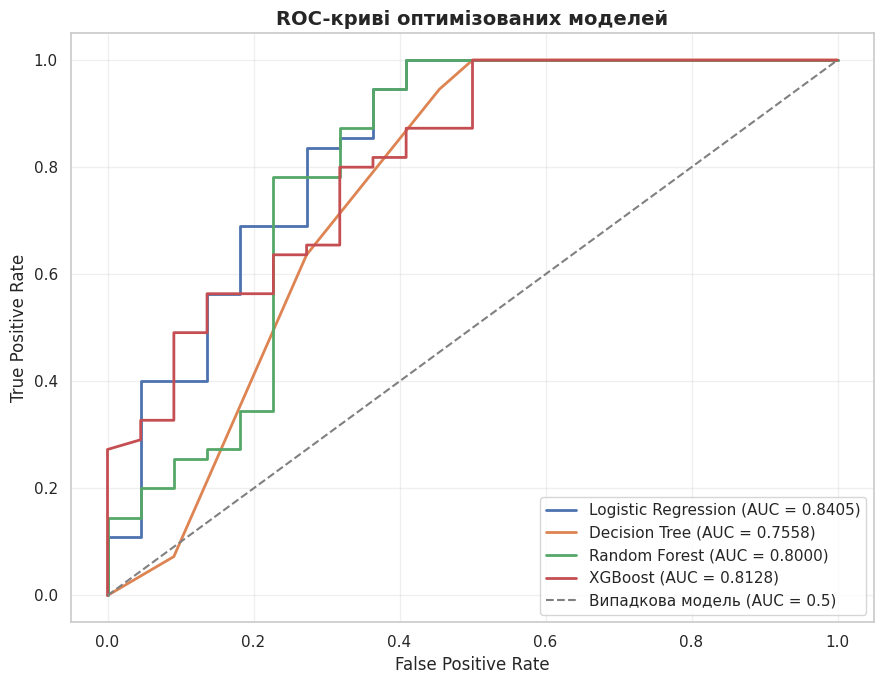

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 7))

for name, model in models.items():

    # Ймовірність схвалення кредиту
    y_proba = model.predict_proba(X_test)[:, 1]

    # ROC-крива
    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_proba
    )

    # Площа під ROC-кривою
    auc = roc_auc_score(
        y_test,
        y_proba
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

# Лінія випадкового класифікатора
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Випадкова модель (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC-криві оптимізованих моделей",
    fontsize=14,
    fontweight="bold"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Logistic Regression показала найкращий результат. Значення ROC-AUC = 0,8405 означає, що приблизно у 84,05% випадково сформованих пар із однієї схваленої та однієї відхиленої заявки модель присвоює вищу прогнозовану ймовірність схваленій заявці.
XGBoost та Random Forest також демонструють достатньо хорошу здатність розрізняти класи. Decision Tree має найнижчий ROC-AUC, хоча його результат усе одно кращий за випадкове ранжування.

In [28]:
# Ймовірності схвалення на навчальній вибірці (CV)
y_proba_train_cv = cross_val_predict(
    grid_logistic.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Пороги для дослідження
thresholds = np.arange(0.3, 0.81, 0.05)

results_threshold = []

for threshold in thresholds:

    # Прогноз за заданим порогом
    y_pred = (
        y_proba_train_cv >= threshold
    ).astype(int)

    # Матриця помилок
    tn, fp, fn, tp = confusion_matrix(
        y_train,
        y_pred,
        labels=[0, 1]
    ).ravel()

    results_threshold.append({
        "Threshold": round(threshold, 2),

        "Accuracy": accuracy_score(
            y_train, y_pred
        ),

        "Precision (1)": precision_score(
            y_train, y_pred,
            zero_division=0
        ),

        "Recall (1)": recall_score(
            y_train, y_pred,
            zero_division=0
        ),

        "Recall (0)": recall_score(
            y_train, y_pred,
            pos_label=0,
            zero_division=0
        ),

        "F1-score (1)": f1_score(
            y_train, y_pred,
            zero_division=0
        ),

        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(results_threshold)

print("Результати аналізу порогів Logistic Regression:")

display(threshold_df.round(4))

Результати аналізу порогів Logistic Regression:


,Threshold,Accuracy,Precision (1),Recall (1),Recall (0),F1-score (1),FP,FN
0,0.30,0.7533,0.7439,0.9954,0.1591,0.8515,74,1
1,0.35,0.7763,0.7643,0.9907,0.2500,0.8629,66,2
2,0.40,0.7928,0.7802,0.9861,0.3182,0.8712,60,3
3,0.45,0.8191,0.8038,0.9861,0.4091,0.8857,52,3
4,0.50,0.8322,0.8161,0.9861,0.4545,0.8931,48,3
5,0.55,0.8257,0.8171,0.9722,0.4659,0.8879,47,6
6,0.60,0.8355,0.8268,0.9722,0.5000,0.8936,44,6
7,0.65,0.8158,0.8279,0.9352,0.5227,0.8783,42,14
8,0.70,0.7500,0.8153,0.8380,0.5341,0.8265,41,35
9,0.75,0.6579,0.8333,0.6481,0.6818,0.7292,28,76


Для оптимізованої моделі Logistic Regression проведено дослідження впливу порогу класифікації на показники якості прогнозування з використанням перехресної валідації навчальної вибірки.
Встановлено, що зі збільшенням порогу класифікації загалом підвищується повнота розпізнавання відхилених кредитних заявок (Recall класу 0), проте зменшується повнота розпізнавання схвалених заявок (Recall класу 1).
Таким чином, серед досліджених значень поріг 0,60 забезпечує найкращий баланс між правильним розпізнаванням обох класів за критерієм Balanced Accuracy. Для остаточного оцінювання ефективності обраного порогу необхідно порівняти результати класифікації на незалежній тестовій вибірці.


Поріг класифікації: 0.50
Accuracy: 0.8571
Balanced Accuracy: 0.75

Звіт класифікації:
               precision    recall  f1-score   support

Відхилено (0)     1.0000    0.5000    0.6667        22
 Схвалено (1)     0.8333    1.0000    0.9091        55

     accuracy                         0.8571        77
    macro avg     0.9167    0.7500    0.7879        77
 weighted avg     0.8810    0.8571    0.8398        77


Поріг класифікації: 0.60
Accuracy: 0.8571
Balanced Accuracy: 0.75

Звіт класифікації:
               precision    recall  f1-score   support

Відхилено (0)     1.0000    0.5000    0.6667        22
 Схвалено (1)     0.8333    1.0000    0.9091        55

     accuracy                         0.8571        77
    macro avg     0.9167    0.7500    0.7879        77
 weighted avg     0.8810    0.8571    0.8398        77



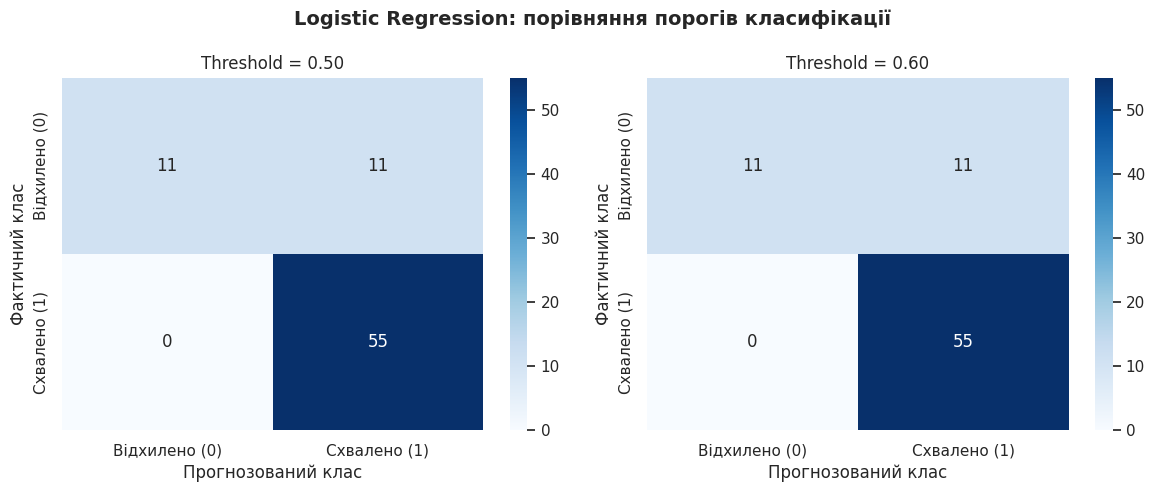

In [30]:
from sklearn.metrics import (
    balanced_accuracy_score
)

# Найкраща оптимізована модель
model = grid_logistic.best_estimator_

# Прогнозовані ймовірності на тестовій вибірці
y_proba_test = model.predict_proba(X_test)[:, 1]

# Пороги для порівняння
thresholds_test = [0.50, 0.60]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, threshold in zip(axes, thresholds_test):

    y_pred = (y_proba_test >= threshold).astype(int)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Відхилено (0)", "Схвалено (1)"],
        yticklabels=["Відхилено (0)", "Схвалено (1)"],
        ax=ax
    )

    ax.set_title(f"Threshold = {threshold:.2f}")
    ax.set_xlabel("Прогнозований клас")
    ax.set_ylabel("Фактичний клас")

    print(f"\nПоріг класифікації: {threshold:.2f}")

    print(
        "Accuracy:",
        round(accuracy_score(y_test, y_pred), 4)
    )

    print(
        "Balanced Accuracy:",
        round(balanced_accuracy_score(y_test, y_pred), 4)
    )

    print("\nЗвіт класифікації:")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=[
                "Відхилено (0)",
                "Схвалено (1)"
            ],
            digits=4,
            zero_division=0
        )
    )

plt.suptitle(
    "Logistic Regression: порівняння порогів класифікації",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Проведено порівняння результатів оптимізованої моделі Logistic Regression за стандартного порогу класифікації 0,50 та порогу 0,60, обраного на основі перехресної валідації навчальної вибірки.
Проте, зміна порогу з 0,50 до 0,60 не покращила результати класифікації на тестовій вибірці.


На основі сукупності отриманих результатів Logistic Regression обрано фінальною моделлю для реалізації вебзастосунку прогнозування схвалення кредитних заявок.

In [34]:
# 1. Фінальна оптимізована модель Logistic Regression
final_model = grid_logistic.best_estimator_

# 2. Перелік предикторів
feature_columns = X_train.columns.to_list()

# 3. Поріг класифікації
classification_threshold = 0.60

# 4. Папка для експорту
output_dir = Path("model_export")
output_dir.mkdir(parents=True, exist_ok=True)

# 5. Збереження всього Pipeline
model_path = output_dir / "loan_logistic_pipeline.pkl"

joblib.dump(final_model, model_path)

# 6. Збереження назв і порядку предикторів
features_path = output_dir / "features.pkl"

joblib.dump(feature_columns, features_path)

# 7. Збереження порогу класифікації
threshold_path = output_dir / "threshold.pkl"

joblib.dump(classification_threshold, threshold_path)

# 8. Контроль результатів
print("Фінальну модель збережено.")
print("Модель:", model_path.resolve())
print("Предиктори:", features_path.resolve())
print("Поріг:", threshold_path.resolve())

print("\nКількість предикторів:", len(feature_columns))
print("\nСписок предикторів:")
print(feature_columns)

print("\nСтруктура Pipeline:")
print(final_model)


Фінальну модель збережено.
Модель: /content/model_export/loan_logistic_pipeline.pkl
Предиктори: /content/model_export/features.pkl
Поріг: /content/model_export/threshold.pkl

Кількість предикторів: 12

Список предикторів:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'LoanIncomeRatio']

Структура Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['ApplicantIncome',
                                                   'Coappl

In [32]:
from google.colab import files

files.download("model_export/loan_logistic_pipeline.pkl")
files.download("model_export/features.pkl")
files.download("model_export/threshold.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import sys
import sklearn
import numpy
import pandas
import joblib

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("joblib:", joblib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
scikit-learn: 1.6.1
numpy: 2.4.6
pandas: 2.2.3
joblib: 1.6.0
